## Import libraries and configure paths

In [1]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Project folders
PROJECT_ROOT = Path.cwd()

# If this notebook is not running from the notebooks folder,
# change PROJECT_ROOT to your RetailPulse folder.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
OUTPUTS_DIR = REPORTS_DIR / "outputs"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data folder exists:", DATA_DIR.exists())
print("Figures folder:", FIGURES_DIR)


Project root: e:\INTERNSHIP\Zidio Development\RetailPulse
Processed data folder exists: True
Figures folder: e:\INTERNSHIP\Zidio Development\RetailPulse\reports\figures


## Load the dataset safely

In [2]:

DATA_FILE = DATA_DIR / "feature_engineered_sales.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}\n"
        "Check the project root and CSV filename."
    )

df = pd.read_csv(DATA_FILE, low_memory=False)

# Standardize column names by removing accidental spaces
df.columns = df.columns.str.strip()

# Convert important columns when present
if "InvoiceDate" in df.columns:
    df["InvoiceDate"] = pd.to_datetime(
        df["InvoiceDate"], errors="coerce"
    )

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(
        df["Date"], errors="coerce"
    )

for col in ["Quantity", "Price", "UnitPrice", "Revenue"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset loaded successfully.")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
display(df.head())


Dataset loaded successfully.
Rows: 779,425
Columns: 48


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue,...,OrdersPerLifetimeDay,ProductQuantity,ProductRevenue,ProductOrders,ProductCustomers,ProductFirstSale,ProductLastSale,ProductAveragePrice,CustomerRevenueShare,ProductRevenueShare
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,...,0.013769,2525,18618.75,432,309,2009-12-01 07:45:00,2011-12-07 14:34:00,7.750915,0.00014,0.001072
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,...,0.013769,2234,13198.10,229,132,2009-12-01 07:45:00,2011-01-11 13:54:00,6.426087,0.00014,0.000760
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,...,0.013769,2948,17384.80,313,174,2009-12-01 07:45:00,2010-09-16 09:07:00,6.398089,0.00014,0.001001
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,...,0.013769,6845,15088.77,319,101,2009-12-01 07:45:00,2011-12-08 12:07:00,2.454954,0.00014,0.000868
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,...,0.013769,34935,40994.71,1893,689,2009-12-01 07:45:00,2011-12-08 15:31:00,1.239695,0.00014,0.002359


## Dataset overview and data quality

In [3]:

# Dataset structure
print("DATASET SHAPE:", df.shape)
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
display(df.dtypes.astype(str).rename("Data Type").to_frame())

# Missing values
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (
        df.isna().mean() * 100
    ).round(2)
}).sort_values("Missing Count", ascending=False)

print("\nMISSING VALUES:")
display(missing_report)

# Duplicate rows
duplicate_count = int(df.duplicated().sum())
print(f"\nDuplicate rows: {duplicate_count:,}")

# Numeric summary
print("\nNUMERIC SUMMARY:")
display(df.describe().T)

# Save quality report
quality_report = {
    "dataset": DATA_FILE.name,
    "rows": int(len(df)),
    "columns": int(len(df.columns)),
    "duplicate_rows": duplicate_count,
    "missing_cells": int(df.isna().sum().sum()),
    "missing_by_column": {
        str(k): int(v)
        for k, v in df.isna().sum().items()
    }
}

with open(
    OUTPUTS_DIR / "eda_data_quality_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(quality_report, f, indent=4)

print("\nSaved: reports/outputs/eda_data_quality_report.json")


DATASET SHAPE: (779425, 48)

COLUMN NAMES:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'IsCancelled', 'Revenue', 'Year', 'Month', 'MonthName', 'Quarter', 'Day', 'DayName', 'DayOfWeek', 'WeekOfYear', 'Date', 'Hour', 'IsWeekend', 'IsWeekday', 'YearMonth', 'WeekStart', 'MonthStart', 'InvoiceQuantity', 'InvoiceRevenue', 'InvoiceItems', 'InvoiceCustomers', 'CustomerRevenue', 'CustomerQuantity', 'CustomerOrders', 'CustomerProducts', 'CustomerCountries', 'FirstPurchase', 'LastPurchase', 'AverageOrderValue', 'CustomerLifetimeDays', 'OrdersPerLifetimeDay', 'ProductQuantity', 'ProductRevenue', 'ProductOrders', 'ProductCustomers', 'ProductFirstSale', 'ProductLastSale', 'ProductAveragePrice', 'CustomerRevenueShare', 'ProductRevenueShare']

DATA TYPES:


,Data Type
Invoice,int64
StockCode,str
Description,str
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
Customer ID,float64
Country,str
IsCancelled,bool
Revenue,float64



MISSING VALUES:


,Missing Count,Missing Percent
Invoice,0,0.0
StockCode,0,0.0
Description,0,0.0
Quantity,0,0.0
InvoiceDate,0,0.0
Price,0,0.0
Customer ID,0,0.0
Country,0,0.0
IsCancelled,0,0.0
Revenue,0,0.0



Duplicate rows: 0

NUMERIC SUMMARY:


,count,mean,min,25%,50%,75%,max,std
Invoice,779425.0,537426.828586,489434.0,514483.0,536754.0,561995.0,581587.0,26901.629627
Quantity,779425.0,13.48937,1.0,2.0,6.0,12.0,80995.0,145.855814
InvoiceDate,779425,2011-01-03 01:44:42.593476,2009-12-01 07:45:00,2010-07-02 14:39:00,2010-12-02 14:09:00,2011-08-01 13:44:00,2011-12-09 12:50:00,NaN
Price,779425.0,3.218488,0.001,1.25,1.95,3.75,10953.5,29.67614
Customer ID,779425.0,15320.360461,12346.0,13971.0,15247.0,16794.0,18287.0,1695.692775
Revenue,779425.0,22.291823,0.001,4.95,12.48,19.8,168469.6,227.427075
Year,779425.0,2010.432051,2009.0,2010.0,2010.0,2011.0,2011.0,0.568385
Month,779425.0,7.417059,1.0,5.0,8.0,11.0,12.0,3.422319
Quarter,779425.0,2.796884,1.0,2.0,3.0,4.0,4.0,1.132107
Day,779425.0,15.390961,1.0,8.0,15.0,23.0,31.0,8.657939



Saved: reports/outputs/eda_data_quality_report.json


## Calculate key sales KPIs

In [4]:

# Find the columns available in this dataset
price_col = next(
    (c for c in ["Price", "UnitPrice"] if c in df.columns),
    None
)

if "Revenue" in df.columns:
    revenue = pd.to_numeric(df["Revenue"], errors="coerce")
elif price_col and "Quantity" in df.columns:
    revenue = (
        pd.to_numeric(df["Quantity"], errors="coerce")
        * pd.to_numeric(df[price_col], errors="coerce")
    )
else:
    raise ValueError(
        "Cannot calculate revenue: need Revenue, "
        "or both Quantity and Price/UnitPrice."
    )

quantity = pd.to_numeric(
    df.get("Quantity", pd.Series(np.nan, index=df.index)),
    errors="coerce"
)

# Exclude explicitly cancelled records if the flag is usable
if "IsCancelled" in df.columns:
    cancel = df["IsCancelled"].astype("string").str.strip().str.lower()
    cancelled = cancel.isin(["true", "1", "yes", "y"])
    sales_mask = ~cancelled
else:
    sales_mask = pd.Series(True, index=df.index)

sales = df.loc[sales_mask].copy()
sales["_EDA_Revenue"] = revenue.loc[sales_mask]
sales["_EDA_Quantity"] = quantity.loc[sales_mask]

invoice_col = next(
    (c for c in ["Invoice", "InvoiceNo"] if c in sales.columns),
    None
)

customer_col = next(
    (c for c in ["Customer ID", "CustomerID"] if c in sales.columns),
    None
)

kpis = {
    "Rows in source dataset": int(len(df)),
    "Rows after excluding cancelled records": int(len(sales)),
    "Cancelled rows": int((~sales_mask).sum()),
    "Total revenue (net of flagged cancellations)": round(
        float(sales["_EDA_Revenue"].sum()), 2
    ),
    "Net quantity": round(
        float(sales["_EDA_Quantity"].sum()), 2
    ),
    "Distinct invoices": (
        int(sales[invoice_col].nunique())
        if invoice_col else None
    ),
    "Distinct identified customers": (
        int(sales[customer_col].nunique())
        if customer_col else None
    ),
    "Distinct products": (
        int(sales["StockCode"].nunique())
        if "StockCode" in sales.columns else None
    ),
    "Distinct countries": (
        int(sales["Country"].nunique())
        if "Country" in sales.columns else None
    ),
    "Negative quantity rows": int((sales["_EDA_Quantity"] < 0).sum()),
    "Negative revenue rows": int((sales["_EDA_Revenue"] < 0).sum())
}

kpi_table = pd.DataFrame(
    {"Metric": list(kpis.keys()), "Value": list(kpis.values())}
)

display(kpi_table)

kpi_table.to_csv(
    OUTPUTS_DIR / "eda_sales_kpis.csv",
    index=False
)
print("Saved: reports/outputs/eda_sales_kpis.csv")


,Metric,Value
0,Rows in source dataset,779425.00
1,Rows after excluding cancelled records,779425.00
2,Cancelled rows,0.00
3,Total revenue (net of flagged cancellations),17374804.27
4,Net quantity,10513952.00
5,Distinct invoices,36969.00
6,Distinct identified customers,5878.00
7,Distinct products,4631.00
8,Distinct countries,41.00
9,Negative quantity rows,0.00


Saved: reports/outputs/eda_sales_kpis.csv


## Analyze monthly and daily sales trends

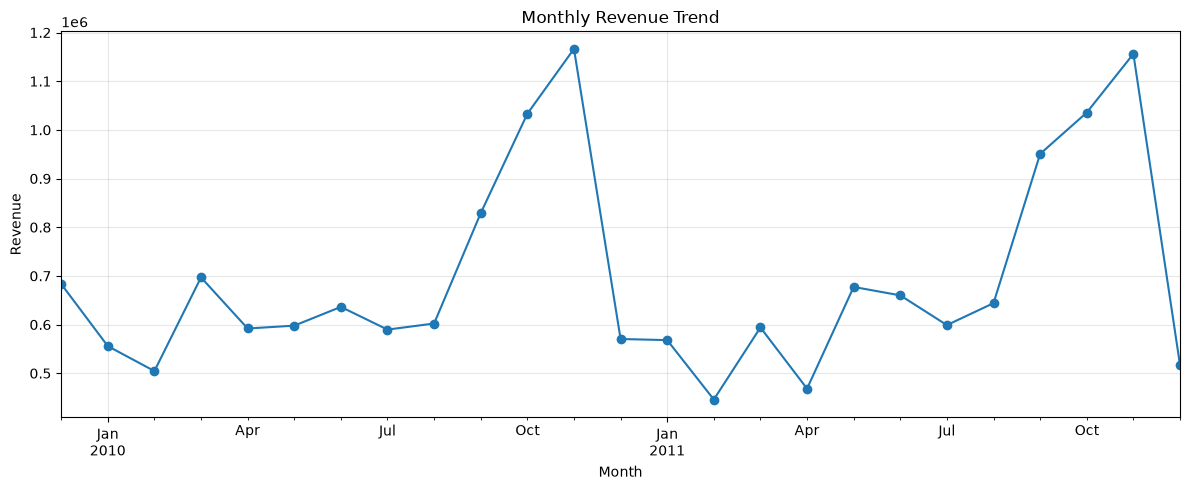

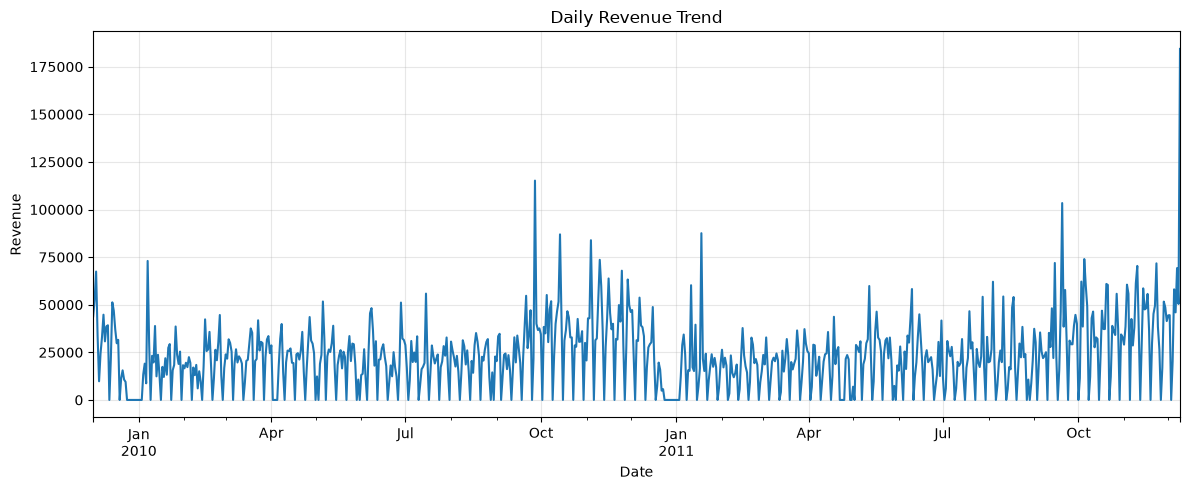

Saved monthly and daily revenue charts.


In [5]:

# Use the best available date column
date_col = next(
    (c for c in ["Date", "InvoiceDate"] if c in sales.columns),
    None
)

if date_col is None:
    print("No date column found; skipping time-series analysis.")
else:
    sales["_EDA_Date"] = pd.to_datetime(
        sales[date_col], errors="coerce"
    )

    dated_sales = sales.dropna(subset=["_EDA_Date"]).copy()

    if dated_sales.empty:
        print("No valid dates available for trend analysis.")
    else:
        # Monthly revenue
        monthly = (
            dated_sales
            .set_index("_EDA_Date")["_EDA_Revenue"]
            .resample("MS")
            .sum()
        )

        fig, ax = plt.subplots(figsize=(12, 5))
        monthly.plot(ax=ax, marker="o")
        ax.set_title("Monthly Revenue Trend")
        ax.set_xlabel("Month")
        ax.set_ylabel("Revenue")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(
            FIGURES_DIR / "eda_monthly_revenue.png",
            dpi=150,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        # Daily revenue
        daily = (
            dated_sales
            .set_index("_EDA_Date")["_EDA_Revenue"]
            .resample("D")
            .sum()
        )

        fig, ax = plt.subplots(figsize=(12, 5))
        daily.plot(ax=ax)
        ax.set_title("Daily Revenue Trend")
        ax.set_xlabel("Date")
        ax.set_ylabel("Revenue")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(
            FIGURES_DIR / "eda_daily_revenue.png",
            dpi=150,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        monthly.rename("Revenue").to_csv(
            OUTPUTS_DIR / "eda_monthly_revenue.csv"
        )

        print("Saved monthly and daily revenue charts.")


## Identify top products and countries

,Revenue
StockCode,
22423,277656.25
85123A,247203.36
23843,168469.60
85099B,167920.64
M,151777.67
POST,124648.04
84879,124351.86
47566,103283.38
23166,81416.73


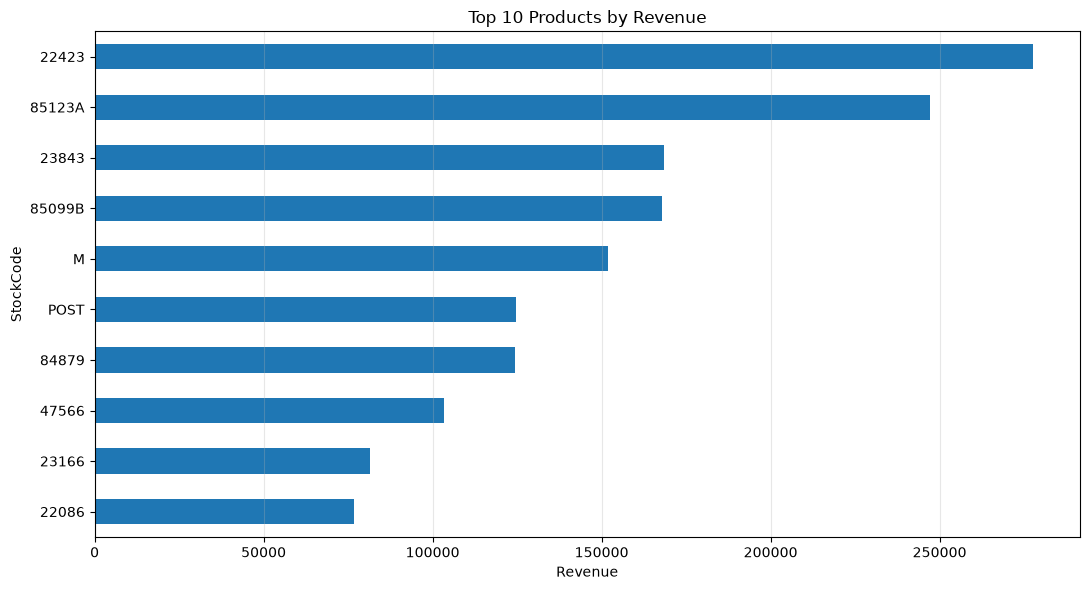

,Revenue
Country,
United Kingdom,1.438923e+07
EIRE,6.165705e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.487690e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.000619e+05
Sweden,9.151582e+04


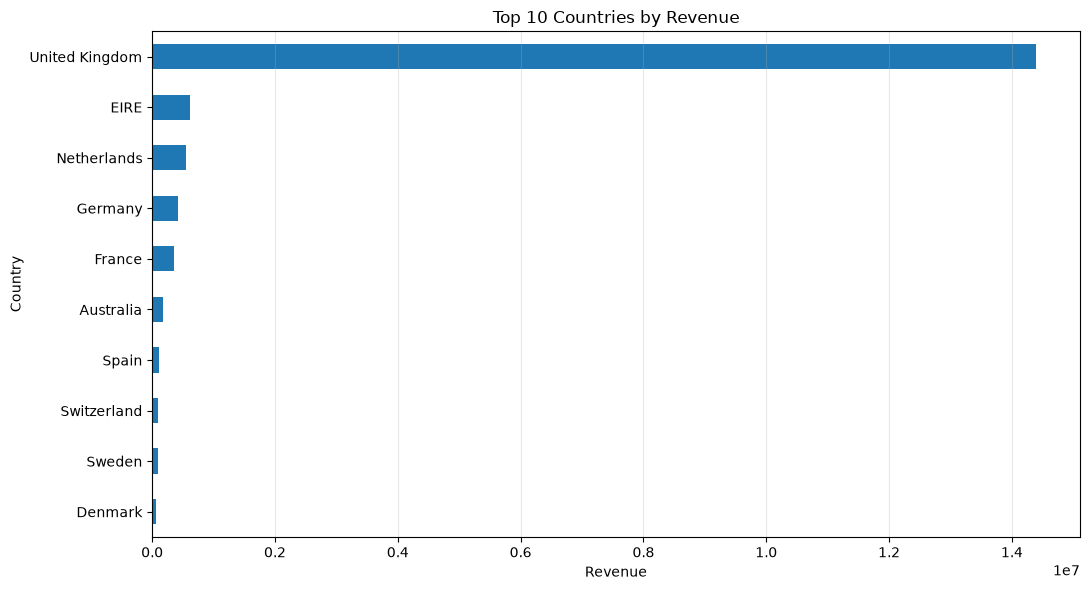

In [6]:

def save_bar_chart(series, title, xlabel, ylabel, filename):
    if series.empty:
        print(f"Skipping empty chart: {title}")
        return

    fig, ax = plt.subplots(figsize=(11, 6))
    series.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


# Top 10 products by revenue
if "StockCode" in sales.columns:
    product_revenue = (
        sales.groupby("StockCode")["_EDA_Revenue"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    display(product_revenue.rename("Revenue").to_frame())

    product_revenue.to_csv(
        OUTPUTS_DIR / "eda_top_products.csv"
    )

    save_bar_chart(
        product_revenue,
        "Top 10 Products by Revenue",
        "Revenue",
        "StockCode",
        "eda_top_products.png"
    )

# Top 10 countries by revenue
if "Country" in sales.columns:
    country_revenue = (
        sales.groupby("Country")["_EDA_Revenue"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    display(country_revenue.rename("Revenue").to_frame())

    country_revenue.to_csv(
        OUTPUTS_DIR / "eda_top_countries.csv"
    )

    save_bar_chart(
        country_revenue,
        "Top 10 Countries by Revenue",
        "Revenue",
        "Country",
        "eda_top_countries.png"
    )


## Customer purchasing patterns

Top 10 customers by revenue:


,Revenue,Quantity,Orders
Customer ID,,,
18102.0,580987.04,181645,145
14646.0,528602.52,367193,151
14156.0,313437.62,164325,156
14911.0,291420.81,147972,398
17450.0,244784.25,83914,51
13694.0,195640.69,188201,143
17511.0,172132.87,117174,60
16446.0,168472.50,80997,2
16684.0,147142.77,104810,55


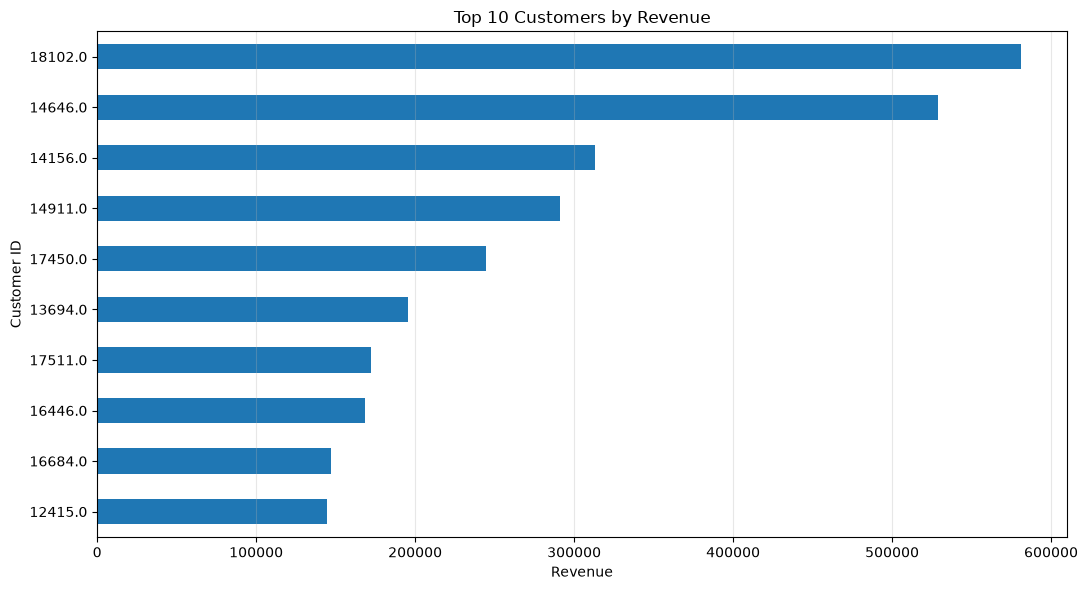

In [7]:

if customer_col:
    identified_sales = sales.dropna(subset=[customer_col]).copy()

    customer_summary = (
        identified_sales.groupby(customer_col)
        .agg(
            Revenue=("_EDA_Revenue", "sum"),
            Quantity=("_EDA_Quantity", "sum"),
            Orders=(invoice_col, "nunique")
            if invoice_col else ("_EDA_Revenue", "size")
        )
        .sort_values("Revenue", ascending=False)
    )

    print("Top 10 customers by revenue:")
    display(customer_summary.head(10))

    customer_summary.to_csv(
        OUTPUTS_DIR / "eda_customer_summary.csv"
    )

    top_customers = customer_summary.head(10)["Revenue"]

    save_bar_chart(
        top_customers,
        "Top 10 Customers by Revenue",
        "Revenue",
        "Customer ID",
        "eda_top_customers.png"
    )
else:
    print("Customer ID column unavailable; skipping customer analysis.")


## Check outliers and cancellation patterns

Quantity outlier rows: 51119


,Invoice,StockCode,Quantity,Price,Country
3,489434,22041,48,2.10,United Kingdom
54,489438,21329,28,0.98,United Kingdom
55,489438,21252,30,1.69,United Kingdom
56,489438,21100,30,1.15,United Kingdom
57,489438,21033,30,2.00,United Kingdom
58,489438,20711,60,1.30,United Kingdom
59,489438,21410,32,2.50,United Kingdom
60,489438,21411,32,2.50,United Kingdom
61,489438,84031A,56,3.00,United Kingdom
62,489438,84031B,56,3.00,United Kingdom


,Rows
IsCancelled,
Not cancelled,779425


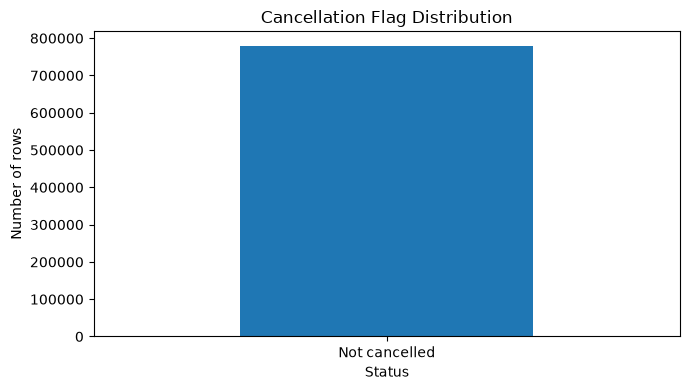

In [8]:

# Quantity outliers using the IQR method
if "Quantity" in sales.columns:
    q1 = sales["_EDA_Quantity"].quantile(0.25)
    q3 = sales["_EDA_Quantity"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    quantity_outliers = sales[
        (sales["_EDA_Quantity"] < lower_bound)
        | (sales["_EDA_Quantity"] > upper_bound)
    ]

    print("Quantity outlier rows:", len(quantity_outliers))
    display(
        quantity_outliers[
            [c for c in [
                invoice_col, "StockCode", "Quantity",
                price_col, "Country"
            ] if c and c in quantity_outliers.columns]
        ].head(10)
    )

# Cancellation distribution from original data
if "IsCancelled" in df.columns:
    cancellation_counts = (
        df["IsCancelled"].astype("string")
        .str.strip().str.lower()
        .map({
            "true": "Cancelled",
            "1": "Cancelled",
            "yes": "Cancelled",
            "y": "Cancelled",
            "false": "Not cancelled",
            "0": "Not cancelled",
            "no": "Not cancelled",
            "n": "Not cancelled"
        })
        .fillna("Unknown")
        .value_counts()
    )

    display(cancellation_counts.rename("Rows").to_frame())

    fig, ax = plt.subplots(figsize=(7, 4))
    cancellation_counts.plot(kind="bar", ax=ax)
    ax.set_title("Cancellation Flag Distribution")
    ax.set_xlabel("Status")
    ax.set_ylabel("Number of rows")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "eda_cancellation_distribution.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


## Save the final EDA summary

In [9]:

eda_summary = {
    "dataset_file": DATA_FILE.name,
    "rows": int(len(df)),
    "columns": int(len(df.columns)),
    "duplicate_rows": int(df.duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
    "revenue_column_used": (
        "Revenue" if "Revenue" in df.columns
        else f"{price_col} * Quantity"
    ),
    "date_column_used": date_col,
    "invoice_column_used": invoice_col,
    "customer_column_used": customer_col,
    "figures_folder": str(FIGURES_DIR.relative_to(PROJECT_ROOT)),
    "outputs_folder": str(OUTPUTS_DIR.relative_to(PROJECT_ROOT))
}

with open(
    OUTPUTS_DIR / "eda_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(eda_summary, f, indent=4)

print("EDA SUMMARY")
print("=" * 40)
for key, value in eda_summary.items():
    print(f"{key}: {value}")

print("\nEDA output files:")
for path in sorted(OUTPUTS_DIR.glob("eda_*")):
    print("-", path.name)

print("\nEDA figures:")
for path in sorted(FIGURES_DIR.glob("eda_*")):
    print("-", path.name)


EDA SUMMARY
dataset_file: feature_engineered_sales.csv
rows: 779425
columns: 48
duplicate_rows: 0
missing_cells: 0
revenue_column_used: Revenue
date_column_used: Date
invoice_column_used: Invoice
customer_column_used: Customer ID
figures_folder: reports\figures
outputs_folder: reports\outputs

EDA output files:
- eda_customer_summary.csv
- eda_data_quality_report.json
- eda_monthly_revenue.csv
- eda_sales_kpis.csv
- eda_summary.json
- eda_top_countries.csv
- eda_top_products.csv

EDA figures:
- eda_cancellation_distribution.png
- eda_daily_revenue.png
- eda_monthly_revenue.png
- eda_top_countries.png
- eda_top_customers.png
- eda_top_products.png


## Final EDA audit

In [10]:

from pathlib import Path
import json
import pandas as pd

# Confirm the paths used by the EDA notebook
required_files = [
    OUTPUTS_DIR / "eda_data_quality_report.json",
    OUTPUTS_DIR / "eda_sales_kpis.csv",
    OUTPUTS_DIR / "eda_summary.json",
]

expected_figures = [
    FIGURES_DIR / "eda_monthly_revenue.png",
    FIGURES_DIR / "eda_daily_revenue.png",
]

print("=" * 55)
print("RETAILPULSE — STEP 4 EDA FINAL AUDIT")
print("=" * 55)

# 1. Check required output files
required_ok = True

for path in required_files:
    exists = path.is_file() and path.stat().st_size > 0
    print(f"{'PASS' if exists else 'FAIL'} | {path.name}")
    required_ok &= exists

# 2. Validate JSON and CSV readability
content_ok = True

if required_ok:
    try:
        with open(
            OUTPUTS_DIR / "eda_data_quality_report.json",
            encoding="utf-8"
        ) as f:
            quality = json.load(f)

        with open(
            OUTPUTS_DIR / "eda_summary.json",
            encoding="utf-8"
        ) as f:
            summary = json.load(f)

        kpis = pd.read_csv(OUTPUTS_DIR / "eda_sales_kpis.csv")

        print("\nQuality report rows:", quality.get("rows"))
        print("Quality report columns:", quality.get("columns"))
        print("KPI records:", len(kpis))
        print("Summary dataset:", summary.get("dataset_file"))

        if kpis.empty:
            content_ok = False
            print("FAIL | KPI file contains no records")
        else:
            print("PASS | KPI CSV is readable")

        if not quality.get("rows") or not quality.get("columns"):
            content_ok = False
            print("FAIL | Quality report has invalid dimensions")

    except Exception as exc:
        content_ok = False
        print("FAIL | Output validation error:", exc)
else:
    content_ok = False

# 3. Check core trend charts
figures_ok = True

for path in expected_figures:
    exists = path.is_file() and path.stat().st_size > 0
    print(f"{'PASS' if exists else 'FAIL'} | {path.name}")
    figures_ok &= exists

# 4. Final result
print("\n" + "=" * 55)

if required_ok and content_ok and figures_ok:
    print("PASS: EDA OUTPUT AUDIT SUCCESSFUL")
    print("Step 4 is ready to mark complete.")
else:
    print("INCOMPLETE: Fix the failed checks above.")
    print("Do not delete existing project data.")

print("=" * 55)


RETAILPULSE — STEP 4 EDA FINAL AUDIT
PASS | eda_data_quality_report.json
PASS | eda_sales_kpis.csv
PASS | eda_summary.json

Quality report rows: 779425
Quality report columns: 48
KPI records: 11
Summary dataset: feature_engineered_sales.csv
PASS | KPI CSV is readable
PASS | eda_monthly_revenue.png
PASS | eda_daily_revenue.png

PASS: EDA OUTPUT AUDIT SUCCESSFUL
Step 4 is ready to mark complete.
